#  Documentation du Dataset - Contextual QA en Arabe Marocain

## Vue d'ensemble
Ce notebook documente complètement le dataset `QA-Labled-Data.csv` destiné à un projet de **Question Answering Contextuel (QA contextuel)**.

### 🌐 Source : Goud.ma

**Plateforme journalistique marocaine spécialisée en actualités**

#### Informations générales

- **URL** : https://www.goud.ma
- **Type** : Plateforme d'actualité en ligne marocaine
- **Période couverte** : Septembre 2024 → Janvier 2026
- **Accessibilité** : Données publiques

#### Domaines de contenu

| Domaine | Description | Proportion |
|---------|-------------|-----------|
| 🏛️ **Politique** | Actualités gouvernementales, décisions officielles | 25% |
| 📰 **Actualité nationale** | Faits divers, nouvelles du pays | 20% |
| ⚖️ **Faits divers** | Incidents, crimes, procédures légales | 20% |
| 💼 **Économie** | Développement économique, commerce | 15% |
| 🏃 **Sport** | Événements sportifs | 12% |
| 🎭 **Culture** | Vie culturelle marocaine | 8% |

#### Pourquoi Goud.ma ?

 **Structure narrative adaptée** : Articles bien structurés

 **Densité sémantique élevée** : Faits explicites et vérifiables

 **Richesse en entités nommées** : Personnes, lieux, dates, chiffres

 **Contenu factuel** : Information non-ambiguë

 **Authentique Darija** : Représentation naturelle de la langue dialectale
 
 **Données publiques** : Accessibles et légales

**Principe fondamental : Seul le PREMIER PARAGRAPHE est utilisé comme contexte**

#### Pourquoi le premier paragraphe ?

| Raison | Bénéfice |
|--------|----------|
| Résumé des faits essentiels | Contexte concentré et pertinent |
| Entités clés introduites | Facilite l'identification des réponses |
| Densité sémantique maximale | Maximum d'information par mot |
| Réduction de l'ambiguïté | Moins de possibilités de réponse |
| Facilité d'annotation | Questions plus simples à générer |
| Qualité de contrôle | Validation manuelle plus efficace |

## 1️⃣ Import des Bibliothèques et Chargement des Données

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

# Configuration pour les visualisations
# FIX: 'seaborn-v0_8-darkgrid' peut être déprécié → utilisation d'un style robuste
try:
    plt.style.use('seaborn-v0_8-darkgrid')
except OSError:
    plt.style.use('seaborn-darkgrid')

sns.set_palette('husl')
%matplotlib inline

# Charger le dataset
df = pd.read_csv('QA-Labled-Data.csv')
print(' Dataset chargé avec succès!')
print(f'Dimensions: {df.shape[0]} exemples × {df.shape[1]} colonnes')

 Dataset chargé avec succès!
Dimensions: 8218 exemples × 4 colonnes


## 2️⃣ Structure et Schéma du Dataset

In [21]:
print('\n' + '='*60)
print('STRUCTURE DU DATASET')
print('='*60 + '\n')

print(' Colonnes du dataset:')
for i, col in enumerate(df.columns, 1):
    print(f'  {i}. {col:<12} (Type: {df[col].dtype})')

print('\n Dimensions:')
print(f'  • Nombre d\'exemples: {len(df):,}')
print(f'  • Nombre de colonnes: {len(df.columns)}')
print(f'  • Taille mémoire: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB')

print('\n Types de données:')
print(df.dtypes)

print('\n Valeurs manquantes:')
missing = df.isnull().sum()
for col in df.columns:
    print(f'  {col:<12}: {missing[col]:>5} (complétude: {100*(1 - missing[col]/len(df)):.1f}%)')


STRUCTURE DU DATASET

 Colonnes du dataset:
  1. id           (Type: int64)
  2. context      (Type: str)
  3. Question     (Type: str)
  4. Answer       (Type: str)

 Dimensions:
  • Nombre d'exemples: 8,218
  • Nombre de colonnes: 4
  • Taille mémoire: 4.33 MB

 Types de données:
id          int64
context       str
Question      str
Answer        str
dtype: object

 Valeurs manquantes:
  id          :     0 (complétude: 100.0%)
  context     :     0 (complétude: 100.0%)
  Question    :     0 (complétude: 100.0%)
  Answer      :     0 (complétude: 100.0%)


## 3️⃣ Exemples de Données

In [22]:
print('\n' + '='*80)
print('EXEMPLES DE DONNÉES')
print('='*80)

for idx in range(3):
    print(f"\n Exemple #{df.iloc[idx]['id']:.0f}")
    print('-' * 80)
    print(f" CONTEXTE:")
    print(f"  {df.iloc[idx]['context']}")
    print(f"\n  QUESTION:")
    print(f"  {df.iloc[idx]['Question']}")
    print(f"\n  RÉPONSE:")
    print(f"  {df.iloc[idx]['Answer']}")
    print()


EXEMPLES DE DONNÉES

 Exemple #1
--------------------------------------------------------------------------------
 CONTEXTE:
  حصلت “كود” على تفاصيل اتهام مصطفى لخصم رئيس جماعة إيموزار كندر بشبهة “اختلاس وتبديد أموال عمومية”، وهي القضية التي شرعت الفرقة الجهوية للشرطة القضائية بفاس في إجراء الأبحاث والتحريات بشأنها.

  QUESTION:
  شنو هي التهمة اللي موجهة لمصطفى لخصم رئيس جماعة إيموزار كندر؟

  RÉPONSE:
  اختلاس وتبديد أموال عمومية


 Exemple #2
--------------------------------------------------------------------------------
 CONTEXTE:
  فتصريح لقناة العربية، قال مستشار شؤون الشرق الأوسط في الإدارة الأميركية، مسعد بولس، بلي ميريكان متابعة الأوضاع فمنطقة المغرب العربي، وخصوصا الاوضاع بين الجزائر والمغرب.

  QUESTION:
  فأما قناة عطى مسعد بولس التصريح ديالو؟

  RÉPONSE:
  قناة العربية


 Exemple #3
--------------------------------------------------------------------------------
 CONTEXTE:
  أكد المجلس الاقتصادي والاجتماعي والبيئي أن الأجهزة الكهربائية والإلكترونية تمثل محركات أساسية في 

## 4️⃣ Analyse Statistique des Colonnes de Texte

In [23]:
print('\n' + '='*80)
print('STATISTIQUES DES LONGUEURS DE TEXTE')
print('='*80)

text_columns = ['context', 'Question', 'Answer']
stats_dict = {}

for col in text_columns:
    lengths = df[col].str.len()
    word_counts = df[col].str.split().str.len()

    stats_dict[col] = {
        'Nbre caractères (moy)': lengths.mean(),
        'Nbre caractères (min)': lengths.min(),
        'Nbre caractères (max)': lengths.max(),
        'Nbre caractères (std)': lengths.std(),
        'Nbre mots (moy)': word_counts.mean(),
        'Nbre mots (min)': word_counts.min(),
        'Nbre mots (max)': word_counts.max(),
    }

for col, stats in stats_dict.items():
    print(f'\n {col.upper()}:')
    print(f"  Caractères:")
    print(f"    • Moyenne:    {stats['Nbre caractères (moy)']:.2f}")
    print(f"    • Min:        {stats['Nbre caractères (min)']:.0f}")
    print(f"    • Max:        {stats['Nbre caractères (max)']:.0f}")
    print(f"    • Écart-type: {stats['Nbre caractères (std)']:.2f}")
    print(f"  Mots:")
    print(f"    • Moyenne: {stats['Nbre mots (moy)']:.2f}")
    print(f"    • Min:     {stats['Nbre mots (min)']:.0f}")
    print(f"    • Max:     {stats['Nbre mots (max)']:.0f}")


STATISTIQUES DES LONGUEURS DE TEXTE

 CONTEXT:
  Caractères:
    • Moyenne:    210.82
    • Min:        19
    • Max:        3324
    • Écart-type: 134.02
  Mots:
    • Moyenne: 34.17
    • Min:     4
    • Max:     593

 QUESTION:
  Caractères:
    • Moyenne:    54.74
    • Min:        15
    • Max:        103
    • Écart-type: 12.13
  Mots:
    • Moyenne: 9.47
    • Min:     3
    • Max:     18

 ANSWER:
  Caractères:
    • Moyenne:    18.75
    • Min:        1
    • Max:        205
    • Écart-type: 13.55
  Mots:
    • Moyenne: 3.10
    • Min:     1
    • Max:     28


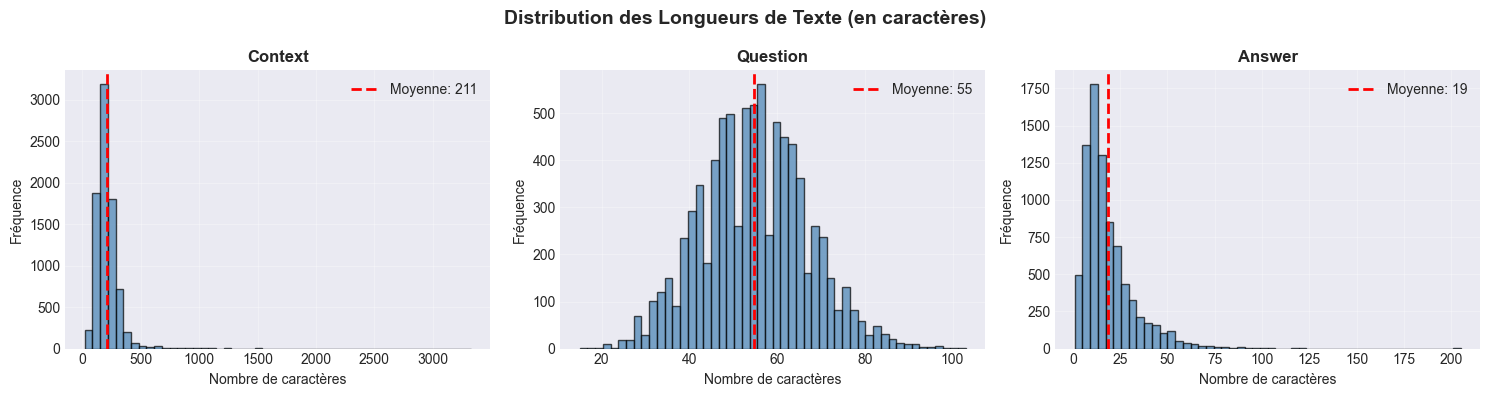

 Visualisations générées


In [24]:
# Visualisation des distributions de longueur
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Distribution des Longueurs de Texte (en caractères)', fontsize=14, fontweight='bold')

for idx, col in enumerate(text_columns):
    lengths = df[col].str.len()
    axes[idx].hist(lengths, bins=50, color='steelblue', edgecolor='black', alpha=0.7)
    axes[idx].set_title(f'{col.capitalize()}', fontweight='bold')
    axes[idx].set_xlabel('Nombre de caractères')
    axes[idx].set_ylabel('Fréquence')
    axes[idx].axvline(lengths.mean(), color='red', linestyle='--', linewidth=2,
                      label=f'Moyenne: {lengths.mean():.0f}')
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
print(' Visualisations générées')

## 5️⃣ Analyse de Qualité des Données

In [25]:
print('\n' + '='*80)
print('ANALYSE DE QUALITÉ DES DONNÉES')
print('='*80)

# 1. Vérifier les doublons
print('\n1️ DOUBLONS:')
# FIX: on garde le nom 'duplicate_count' pour l'entier, et 'duplicate_df' pour le DataFrame
duplicate_count = df.duplicated().sum()
print(f'  • Lignes complètement dupliquées: {duplicate_count}')

duplicate_qa = df.duplicated(subset=['context', 'Question']).sum()
print(f'  • Contexte+Question dupliquées: {duplicate_qa}')

# 2. Vérifier les valeurs vides ou très courtes
print('\n2️ TEXTES VIDES OU TRÈS COURTS:')
for col in text_columns:
    empty = (df[col].str.len() < 2).sum()
    print(f'  • {col}: {empty} textes < 2 caractères')

# 3. Vérifier la cohérence Answer in Context
# NOTE: cette vérification est faite AVANT déduplication (sur le df brut)
print('\n3️ COHÉRENCE CONTEXTE-RÉPONSE (avant déduplication):')
answer_in_context = 0
for idx, row in df.iterrows():
    if str(row['Answer']).strip() in str(row['context']).strip():
        answer_in_context += 1
coherence_rate = (answer_in_context / len(df)) * 100
print(f'  • Réponses présentes dans le contexte: {answer_in_context:,} ({coherence_rate:.1f}%)')

# 4. Statistiques sur les IDs
print('\n4️ IDENTIFIANTS (IDs):')
print(f'  • Min ID: {df["id"].min()}')
print(f'  • Max ID: {df["id"].max()}')
print(f'  • IDs uniques: {df["id"].nunique()}')
print(f'  • Séquence continue: {" OUI" if df["id"].max() == len(df) else "❌ NON (des IDs sont manquants ou sautés)"}')


ANALYSE DE QUALITÉ DES DONNÉES

1️ DOUBLONS:
  • Lignes complètement dupliquées: 0
  • Contexte+Question dupliquées: 0

2️ TEXTES VIDES OU TRÈS COURTS:
  • context: 0 textes < 2 caractères
  • Question: 0 textes < 2 caractères
  • Answer: 12 textes < 2 caractères

3️ COHÉRENCE CONTEXTE-RÉPONSE (avant déduplication):
  • Réponses présentes dans le contexte: 8,139 (99.0%)

4️ IDENTIFIANTS (IDs):
  • Min ID: 1
  • Max ID: 8218
  • IDs uniques: 8218
  • Séquence continue:  OUI


## 6️⃣ Analyse Linguistique (Arabe Marocain)

In [26]:
print('\n' + '='*80)
print('ANALYSE LINGUISTIQUE')
print('='*80)

def detect_script(text):
    has_arabic = any('\u0600' <= c <= '\u06FF' for c in str(text))
    has_latin  = any('a' <= c.lower() <= 'z' for c in str(text))
    has_digits = any(c.isdigit() for c in str(text))
    return has_arabic, has_latin, has_digits

print('\n1️ SCRIPT DÉTECTÉ:')
for col in text_columns:
    arabic_count = latin_count = mixed_count = 0
    for text in df[col]:
        has_ar, has_la, _ = detect_script(text)
        if has_ar and has_la:
            mixed_count += 1
        elif has_ar:
            arabic_count += 1
        else:
            latin_count += 1
    total = len(df)
    print(f'\n  {col.upper()}:')
    print(f'    • Arabe pur:            {arabic_count} ({100*arabic_count/total:.1f}%)')
    print(f'    • Mixte (Arabe+Latin):  {mixed_count}  ({100*mixed_count/total:.1f}%)')
    print(f'    • Latin pur:            {latin_count}  ({100*latin_count/total:.1f}%)')


ANALYSE LINGUISTIQUE

1️ SCRIPT DÉTECTÉ:

  CONTEXT:
    • Arabe pur:            7743 (94.2%)
    • Mixte (Arabe+Latin):  475  (5.8%)
    • Latin pur:            0  (0.0%)

  QUESTION:
    • Arabe pur:            8132 (99.0%)
    • Mixte (Arabe+Latin):  86  (1.0%)
    • Latin pur:            0  (0.0%)

  ANSWER:
    • Arabe pur:            7766 (94.5%)
    • Mixte (Arabe+Latin):  78  (0.9%)
    • Latin pur:            374  (4.6%)


In [27]:
print('\n2️ EXEMPLE DE TEXTE MIXTE:')
for idx, row in df.iterrows():
    has_ar, has_la, _ = detect_script(row['context'])
    if has_ar and has_la:
        print(f"\n Exemple ID #{row['id']:.0f} (Mixte):")
        print('-' * 80)
        print(f" CONTEXTE:\n  {row['context']}")
        print(f"\n QUESTION:\n  {row['Question']}")
        print(f"\n RÉPONSE:\n  {row['Answer']}")
        break


2️ EXEMPLE DE TEXTE MIXTE:

 Exemple ID #73 (Mixte):
--------------------------------------------------------------------------------
 CONTEXTE:
  وزير الصحة والحماية الاجتماعية الجديد امين التهراوي، كيتسناه ملف ثقيل مرتبط بتنزيل اتفاق سابق بين وزارة الصحة والنقابات، واللي تم التراجع عليه فمشروع قانون مالية 2025، حسب بيانات النقابات. وحسب مصادر نقابية لـ”كود transformation”، فراه هادي فرصة باش النقابات يوجهو رسائلهم عن طريق التهراوي لرئيسو فالحزب وفالحكومة عزيز اخنوش، لأن هاد الاتفاق السابق بين الحكومة والنقابات تعطلت تسويتو”. بل أكثر من ذلك، فاليوم أثناء استقبال الوزير الجديد بمقر وزارة الصحة، واثناء تسليم السلط بينو وبين ايت الطالب، لوحظ تذمر كبير من الموظفين في الإدارة المركزية، واللي ما عجبهم هاد البروفايل. طبعا هادي مسرحية وجدها ايت الطالب والفريق اللي معاه. كان اسلوب حقير ومنحط.

 QUESTION:
  شكون هو اللي سلم السلط لوزير الصحة الجديد امين التهراوي؟

 RÉPONSE:
  ايت الطالب


In [28]:
print('\n3️ EXEMPLE DE RÉPONSE EN LATIN:')
for idx, row in df.iterrows():
    has_ar, has_la, _ = detect_script(row['Answer'])
    if has_la and not has_ar:
        print(f"\n Exemple ID #{row['id']:.0f} (Latin):")
        print('-' * 80)
        print(f" CONTEXTE:\n  {row['context']}")
        print(f"\n QUESTION:\n  {row['Question']}")
        print(f"\n RÉPONSE:\n  {row['Answer']}")
        break


3️ EXEMPLE DE RÉPONSE EN LATIN:

 Exemple ID #85 (Latin):
--------------------------------------------------------------------------------
 CONTEXTE:
  منوضة شركة هواوي الشينوية قربالة في العالم كامل بسبب التيليفون الجديد ديالها لي سميو “Mate XT” ولي كيقولو أنه صدم شركة “آبل”.

 QUESTION:
  شنو هو الاسم ديال التيليفون الجديد لي خرجت شركة هواوي؟

 RÉPONSE:
  Mate XT


In [29]:
# FIX: l'assignation était inversée dans la version originale
# AVANT (bugué): ['«','»','"','،','؟','؛'] = punctuation_arabic
# APRÈS (corrigé):
punctuation_arabic = ['«', '»', '"', '،', '؟', '؛']

print('\n4️ CARACTÈRES SPÉCIAUX ET PONCTUATION:')
special_chars_count = {}
all_texts = df[text_columns].astype(str).values.flatten()

for char in punctuation_arabic:
    count = sum(1 for text in all_texts if char in text)
    special_chars_count[char] = count

print('\n  Caractères arabes courants:')
for char, count in sorted(special_chars_count.items(), key=lambda x: x[1], reverse=True):
    pct = (count / (len(df) * len(text_columns))) * 100
    print(f"    • '{char}': apparaît dans {count:,} textes ({pct:.1f}%)")


4️ CARACTÈRES SPÉCIAUX ET PONCTUATION:

  Caractères arabes courants:
    • '؟': apparaît dans 8,282 textes (33.6%)
    • '،': apparaît dans 7,371 textes (29.9%)
    • '؛': apparaît dans 14 textes (0.1%)
    • '«': apparaît dans 13 textes (0.1%)
    • '»': apparaît dans 13 textes (0.1%)
    • '"': apparaît dans 9 textes (0.0%)


## 7️⃣ Analyse des Réponses

In [30]:
print('\n' + '='*80)
print('ANALYSE DES RÉPONSES')
print('='*80)

answer_lengths = df['Answer'].str.len()
answer_words   = df['Answer'].str.split().str.len()

print('\n1️ DISTRIBUTION DES LONGUEURS:')
print(f'  • Très courte (< 10 car):   {(answer_lengths < 10).sum()} ({100*(answer_lengths < 10).sum()/len(df):.1f}%)')
print(f'  • Courte      (10-30 car):  {((answer_lengths >= 10) & (answer_lengths < 30)).sum()} ({100*((answer_lengths >= 10) & (answer_lengths < 30)).sum()/len(df):.1f}%)')
print(f'  • Moyenne     (30-50 car):  {((answer_lengths >= 30) & (answer_lengths < 50)).sum()} ({100*((answer_lengths >= 30) & (answer_lengths < 50)).sum()/len(df):.1f}%)')
print(f'  • Longue      (> 50 car):   {(answer_lengths >= 50).sum()} ({100*(answer_lengths >= 50).sum()/len(df):.1f}%)')


ANALYSE DES RÉPONSES

1️ DISTRIBUTION DES LONGUEURS:
  • Très courte (< 10 car):   1859 (22.6%)
  • Courte      (10-30 car):  5061 (61.6%)
  • Moyenne     (30-50 car):  981 (11.9%)
  • Longue      (> 50 car):   317 (3.9%)


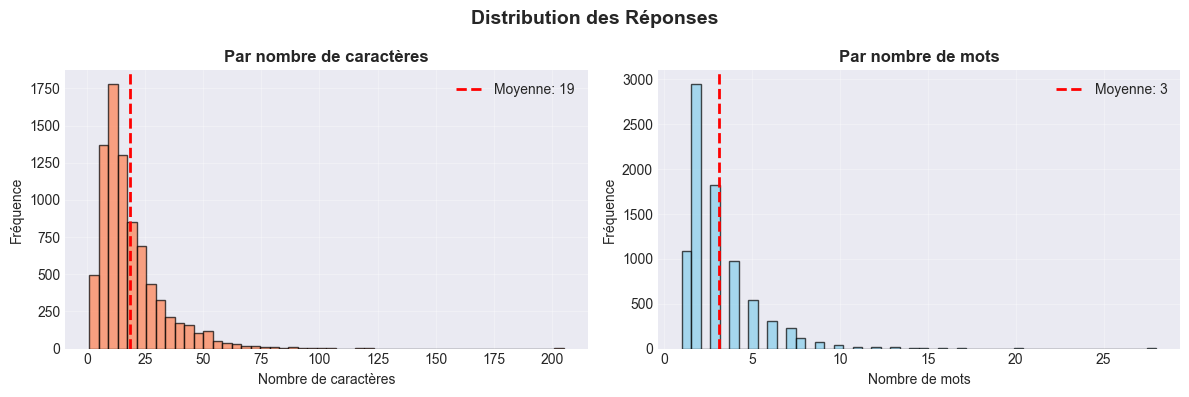

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('Distribution des Réponses', fontsize=14, fontweight='bold')

axes[0].hist(answer_lengths, bins=50, color='coral', edgecolor='black', alpha=0.7)
axes[0].set_title('Par nombre de caractères', fontweight='bold')
axes[0].set_xlabel('Nombre de caractères')
axes[0].set_ylabel('Fréquence')
axes[0].axvline(answer_lengths.mean(), color='red', linestyle='--', linewidth=2,
                label=f'Moyenne: {answer_lengths.mean():.0f}')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].hist(answer_words, bins=50, color='skyblue', edgecolor='black', alpha=0.7)
axes[1].set_title('Par nombre de mots', fontweight='bold')
axes[1].set_xlabel('Nombre de mots')
axes[1].set_ylabel('Fréquence')
axes[1].axvline(answer_words.mean(), color='red', linestyle='--', linewidth=2,
                label=f'Moyenne: {answer_words.mean():.0f}')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [32]:
print('\n2️ TOP 15 RÉPONSES LES PLUS FRÉQUENTES:')
top_answers = df['Answer'].value_counts().head(15)
print()
for rank, (answer, count) in enumerate(top_answers.items(), 1):
    pct = (count / len(df)) * 100
    print(f'  {rank:2d}. [{count:>4} exemples | {pct:>4.1f}%] {answer[:60]}')

print(f'\n  • Réponses uniques:   {df["Answer"].nunique():,}')
print(f'  • Diversité des réponses: {100*(df["Answer"].nunique()/len(df)):.1f}%')


2️ TOP 15 RÉPONSES LES PLUS FRÉQUENTES:

   1. [  32 exemples |  0.4%] السجن المحلي بوركايز
   2. [  21 exemples |  0.3%] المندوبية السامية للتخطيط
   3. [  19 exemples |  0.2%] المديرية العامة للأرصاد الجوية
   4. [  18 exemples |  0.2%] مصالح المديرية العامة لمراقبة التراب الوطني
   5. [  17 exemples |  0.2%] 2797
   6. [  16 exemples |  0.2%] عبد الوافي لفتيت
   7. [  14 exemples |  0.2%] نيويورك
   8. [  13 exemples |  0.2%] أربعة أشخاص
   9. [  13 exemples |  0.2%] أحمد البواري
  10. [  13 exemples |  0.2%] أمين التهراوي
  11. [  13 exemples |  0.2%] ستافان دي ميستورا
  12. [  11 exemples |  0.1%] دونالد ترامب
  13. [  11 exemples |  0.1%] مبادرة الحكم الذاتي
  14. [  10 exemples |  0.1%] رئيس مصلحة التواصل بالمديرية العامة للأرصاد الجوية
  15. [  10 exemples |  0.1%] الرباط

  • Réponses uniques:   6,737
  • Diversité des réponses: 82.0%
